## Business Problem

Heart disease is one of the leading causes of death worldwide. Identifying patients who are at risk early can help doctors intervene sooner with lifestyle changes, medication, or further testing. Manually reviewing every patient's health metrics is slow and inconsistent across clinicians. An automated model that flags high-risk patients from routine health data can support faster, more consistent screening.

## Problem Statement

Develop an Artificial Neural Network (ANN) model to predict whether a patient is likely to have heart disease based on health-related features such as age, gender, resting blood pressure, cholesterol, fasting blood sugar, resting ECG results, maximum heart rate, exercise-induced angina, smoking status, BMI, physical activity level, and family history.

In [3]:
import pandas as pd
import numpy as np

In [4]:
df=pd.read_csv(r"C:\Users\Hello\Downloads\heart_disease_dataset (1).csv")
df.head()

,age,gender,resting_bp,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,smoking_status,bmi,physical_activity,family_history,heart_disease
0,25,Female,152.0,217.0,0,ST-T Abnormality,147.0,0,never,24.2,high,0,0
1,67,Male,132.0,140.0,0,Normal,157.0,0,never,28.5,low,1,0
2,59,Female,130.0,232.0,0,Normal,157.0,0,never,23.9,low,1,0
3,46,Male,147.0,232.0,0,ST-T Abnormality,124.0,0,former,20.6,medium,0,0
4,46,Female,160.0,195.0,0,Normal,162.0,1,never,25.6,medium,0,0


In [5]:
df.shape

(100000, 13)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   age                  100000 non-null  int64  
 1   gender               100000 non-null  object 
 2   resting_bp           100000 non-null  float64
 3   cholesterol          100000 non-null  float64
 4   fasting_blood_sugar  100000 non-null  int64  
 5   resting_ecg          100000 non-null  object 
 6   max_heart_rate       100000 non-null  float64
 7   exercise_angina      100000 non-null  int64  
 8   smoking_status       100000 non-null  object 
 9   bmi                  100000 non-null  float64
 10  physical_activity    100000 non-null  object 
 11  family_history       100000 non-null  int64  
 12  heart_disease        100000 non-null  int64  
dtypes: float64(4), int64(5), object(4)
memory usage: 9.9+ MB


In [7]:
df.describe()

,age,resting_bp,cholesterol,fasting_blood_sugar,max_heart_rate,exercise_angina,bmi,family_history,heart_disease
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,49.990970,130.12536,220.195620,0.148590,149.832770,0.300110,27.027170,0.248550,0.143990
std,17.603732,16.82023,44.415457,0.355686,21.970204,0.458308,4.955841,0.432174,0.351081
min,20.000000,90.00000,120.000000,0.000000,70.000000,0.000000,15.000000,0.000000,0.000000
25%,35.000000,119.00000,190.000000,0.000000,135.000000,0.000000,23.700000,0.000000,0.000000
50%,50.000000,130.00000,220.000000,0.000000,150.000000,0.000000,27.000000,0.000000,0.000000
75%,65.000000,142.00000,250.000000,0.000000,165.000000,1.000000,30.400000,0.000000,0.000000
max,80.000000,200.00000,400.000000,1.000000,210.000000,1.000000,48.600000,1.000000,1.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

age                    0
gender                 0
resting_bp             0
cholesterol            0
fasting_blood_sugar    0
resting_ecg            0
max_heart_rate         0
exercise_angina        0
smoking_status         0
bmi                    0
physical_activity      0
family_history         0
heart_disease          0
dtype: int64

### Data preprocessing

In [10]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [11]:
num_col = ["age","resting_bp","cholesterol","fasting_blood_sugar","max_heart_rate","exercise_angina","bmi","family_history"]
cat_col = ["gender","resting_ecg","smoking_status","physical_activity"]

In [12]:
num_pipe=Pipeline([('scaling',StandardScaler())])
cat_pipe=Pipeline([('Encoder',OneHotEncoder(handle_unknown='ignore',drop='first'))])

In [13]:
preprocessor=ColumnTransformer([('Scaling',num_pipe,num_col),
                                ('Encodig',cat_pipe,cat_col)])

In [14]:
x = df.drop("heart_disease", axis=1)
y = df["heart_disease"]

In [15]:
x_prep=preprocessor.fit_transform(x)
x_prep

array([[-1.41964758,  1.30050235, -0.07194874, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.96622213,  0.11145206, -1.80558809, ...,  1.        ,
         1.        ,  0.        ],
       [ 0.51177076, -0.00745297,  0.26577322, ...,  1.        ,
         1.        ,  0.        ],
       ...,
       [ 0.28454507,  0.28980961, -0.63481866, ...,  1.        ,
         0.        ,  0.        ],
       [-1.70367968, -1.55321835,  0.15319923, ...,  1.        ,
         1.        ,  0.        ],
       [ 1.53428634,  0.34926212,  0.62600997, ...,  0.        ,
         0.        ,  1.        ]], shape=(100000, 15))

In [16]:
x_train, x_test, y_train, y_test = train_test_split(
    x_prep,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [17]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((80000, 15), (20000, 15), (80000,), (20000,))

### Model Build

In [1]:
from keras.models import Sequential
from keras.layers import Input,Dense

In [20]:
model=Sequential()
model.add(Input(shape=(x_train.shape[1],)))
model.add(Dense(32,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 545 (2.13 KB)

 Trainable params: 545 (2.13 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [23]:
model.fit(x_train,y_train,epochs=20,validation_data=(x_test,y_test),batch_size=128)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.8298 - loss: 0.3964 - val_accuracy: 0.8585 - val_loss: 0.3481
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8617 - loss: 0.3468 - val_accuracy: 0.8596 - val_loss: 0.3444
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8621 - loss: 0.3446 - val_accuracy: 0.8608 - val_loss: 0.3434
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8622 - loss: 0.3439 - val_accuracy: 0.8605 - val_loss: 0.3429
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8624 - loss: 0.3437 - val_accuracy: 0.8601 - val_loss: 0.3427
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8625 - loss: 0.3434 - val_accuracy: 0.8612 - val_loss: 0.3426
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8624 - loss: 0.3431 - val_accuracy: 0.8608 - val_loss: 0.3426
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8628 - loss: 0.3429 - val_accuracy: 0

In [24]:
import seaborn as sns

<Axes: >

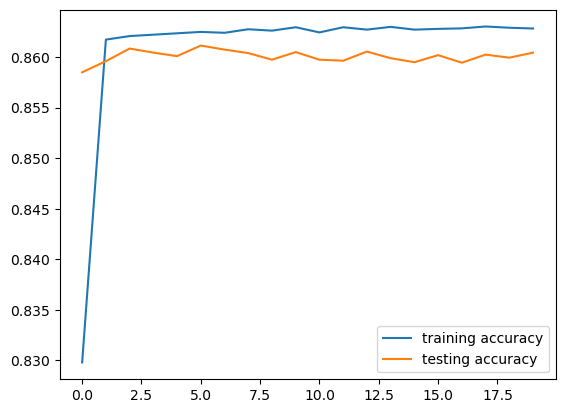

In [25]:
sns.lineplot(x=model.history.epoch,y=model.history.history['accuracy'],label='training accuracy')
sns.lineplot(x=model.history.epoch,y=model.history.history['val_accuracy'],label='testing accuracy')

<Axes: >

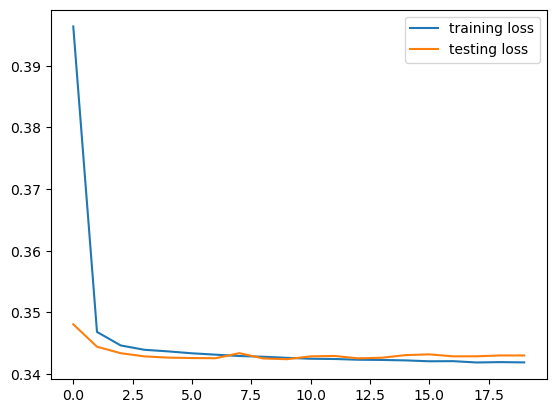

In [26]:
sns.lineplot(x=model.history.epoch,y=model.history.history['loss'],label='training loss')
sns.lineplot(x=model.history.epoch,y=model.history.history['val_loss'],label='testing loss')

In [27]:
from sklearn.metrics import classification_report

In [28]:
y_pred=np.where(model.predict(x_test)>0.5,1,0)
y_pred

625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


array([[0],
       [0],
       [0],
       ...,
       [0],
       [0],
       [0]], shape=(20000, 1))

In [29]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.87      0.99      0.92     17120
           1       0.58      0.12      0.19      2880

    accuracy                           0.86     20000
   macro avg       0.72      0.55      0.56     20000
weighted avg       0.83      0.86      0.82     20000



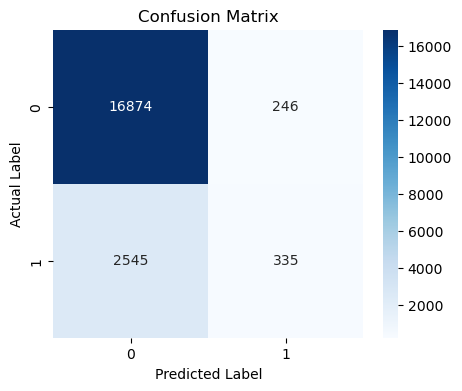

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [31]:
from sklearn.utils.class_weight import compute_class_weight

In [32]:
class_weight=compute_class_weight(class_weight='balanced',classes=np.unique(y_train),y=y_train)
dict_class={i:class_weight[i] for i in range(len(class_weight))}
dict_class

{0: np.float64(0.5841036199821849), 1: np.float64(3.4725236565674105)}

In [36]:
import optuna
from keras.regularizers import L1L2

In [37]:
from keras.optimizers import Adam,RMSprop,SGD
from keras.layers import Dropout,BatchNormalization
from keras.regularizers import L1L2
from keras.callbacks import EarlyStopping

def objective(trail):
    n_layers=trail.suggest_int('n_layers',1,10)
    epochs=trail.suggest_int('epochs',1,10)
    lr_rate=trail.suggest_float('learning rate',1e-4,1e-2,log=True)
    batch_size=trail.suggest_int('batch_size',12,128)
    activation=trail.suggest_categorical('activation',['relu','tanh'])
    optimizers=trail.suggest_categorical('optimizers',['Adam','RMSprop','SGD'])

    model=Sequential()
    model.add(Input(shape=(x_train.shape[1],)))

    for i in range(n_layers):

        n_units=trail.suggest_int(f'units{i}',1,100)
        dropout=trail.suggest_float(f'dropout{i}',0.1,0.5)
        strength=trail.suggest_float(f'regularization{i}',1e-4,1e-2,log=True)

        model.add(Dense(units=n_units,activation=activation,kernel_regularizer=L1L2(l1=strength,l2=strength)))
        model.add(Dropout(rate=dropout))
        model.add(BatchNormalization())

    model.add(Dense(1,activation='sigmoid'))

    early_stopping=EarlyStopping(monitor='val_recall',min_delta=0.001,patience=3)

    if optimizers=='Adam':
        optimizer=Adam(learning_rate=lr_rate)
    elif optimizers=='RMSprop':
        optimizer=RMSprop(learning_rate=lr_rate)
    else:
        optimizer=SGD(learning_rate=lr_rate)

    model.compile(optimizer=optimizer,loss='binary_crossentropy',metrics=['recall'])

    model.fit(x_train,y_train,epochs=epochs,batch_size=batch_size,validation_data=(x_test,y_test),class_weight=dict_class,callbacks=early_stopping)

    return max(model.history.history['val_recall'])

In [38]:
study=optuna.create_study(direction='maximize')
study.optimize(objective,n_trials=5)

[I 2026-08-15 12:15:34,399] A new study created in memory with name: no-name-56c30007-5aa3-4314-b73b-68cafaefd1dc


Epoch 1/3
964/964 ━━━━━━━━━━━━━━━━━━━━ 23s 11ms/step - loss: 1.3911 - recall: 0.6399 - val_loss: 1.2240 - val_recall: 0.7958
Epoch 2/3
964/964 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 1.0628 - recall: 0.7213 - val_loss: 0.9321 - val_recall: 0.7847
Epoch 3/3
964/964 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 0.8438 - recall: 0.7336 - val_loss: 0.7789 - val_recall: 0.7618


[I 2026-08-15 12:16:17,498] Trial 0 finished with value: 0.7958333492279053 and parameters: {'n_layers': 7, 'epochs': 3, 'learning rate': 0.0005060879527760553, 'batch_size': 83, 'activation': 'tanh', 'optimizers': 'Adam', 'units0': 10, 'dropout0': 0.2106718706864165, 'regularization0': 0.002442375750968614, 'units1': 60, 'dropout1': 0.23521308138605546, 'regularization1': 0.00013609307218909257, 'units2': 46, 'dropout2': 0.3000972905889734, 'regularization2': 0.00010403761193746155, 'units3': 14, 'dropout3': 0.25164688287029074, 'regularization3': 0.00015230364829961138, 'units4': 97, 'dropout4': 0.2504655095998053, 'regularization4': 0.0012698933074518218, 'units5': 75, 'dropout5': 0.36904673068524596, 'regularization5': 0.0004989317827471317, 'units6': 10, 'dropout6': 0.17777710649313816, 'regularization6': 0.00014523418571606912}. Best is trial 0 with value: 0.7958333492279053.


Epoch 1/2
762/762 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step - loss: 3.3967 - recall: 0.5675 - val_loss: 3.0081 - val_recall: 0.8014
Epoch 2/2
762/762 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 2.6680 - recall: 0.6481 - val_loss: 2.3659 - val_recall: 0.7983


[I 2026-08-15 12:16:44,786] Trial 1 finished with value: 0.8013888597488403 and parameters: {'n_layers': 7, 'epochs': 2, 'learning rate': 0.0001843071924884385, 'batch_size': 105, 'activation': 'tanh', 'optimizers': 'RMSprop', 'units0': 70, 'dropout0': 0.15359185166756478, 'regularization0': 0.006030589431024456, 'units1': 68, 'dropout1': 0.15909622709212312, 'regularization1': 0.00032268338788105804, 'units2': 2, 'dropout2': 0.3718032182227572, 'regularization2': 0.0036348393591345194, 'units3': 83, 'dropout3': 0.3758040751030888, 'regularization3': 0.00268717738439356, 'units4': 71, 'dropout4': 0.3702771000131908, 'regularization4': 0.0010382893077901158, 'units5': 78, 'dropout5': 0.13137531954723639, 'regularization5': 0.0011033239312242039, 'units6': 100, 'dropout6': 0.18754987813498578, 'regularization6': 0.00030845155320858707}. Best is trial 1 with value: 0.8013888597488403.


...

[I 2026-08-15 12:18:02,889] Trial 2 finished with value: 0.7684027552604675 and parameters: {'n_layers': 9, 'epochs': 10, 'learning rate': 0.005087642326637324, 'batch_size': 101, 'activation': 'tanh', 'optimizers': 'Adam', 'units0': 68, 'dropout0': 0.4708259863866838, 'regularization0': 0.0014077115755713853, 'units1': 40, 'dropout1': 0.15850611810195217, 'regularization1': 0.0015746126869245157, 'units2': 21, 'dropout2': 0.31918678991782234, 'regularization2': 0.0003021382801662592, 'units3': 40, 'dropout3': 0.29840374710408946, 'regularization3': 0.0017869803426913864, 'units4': 13, 'dropout4': 0.1870007262471138, 'regularization4': 0.00010868350849883599, 'units5': 19, 'dropout5': 0.1344178809093639, 'regularization5': 0.001310250026941558, 'units6': 56, 'dropout6': 0.3900942002839066, 'regularization6': 0.00219393644722713, 'units7': 54, 'dropout7': 0.2756359060730076, 'regularization7': 0.002044187973233574, 'units8': 94, 'dropout8': 0.17693673994507414, 'regularization8': 0.0004

Epoch 1/2
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 35s 11ms/step - loss: 2.3880 - recall: 0.6791 - val_loss: 1.0183 - val_recall: 0.7934
Epoch 2/2
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - loss: 0.8601 - recall: 0.6979 - val_loss: 0.8414 - val_recall: 0.7694


[I 2026-08-15 12:18:58,823] Trial 3 finished with value: 0.7934027910232544 and parameters: {'n_layers': 9, 'epochs': 2, 'learning rate': 0.0008476108645406383, 'batch_size': 40, 'activation': 'tanh', 'optimizers': 'Adam', 'units0': 100, 'dropout0': 0.11310652714099906, 'regularization0': 0.00012300847929717234, 'units1': 50, 'dropout1': 0.20215569195512106, 'regularization1': 0.0010505911692821215, 'units2': 58, 'dropout2': 0.22997072377996447, 'regularization2': 0.006939682523358892, 'units3': 58, 'dropout3': 0.4829431942780271, 'regularization3': 0.001822997605649707, 'units4': 69, 'dropout4': 0.25368568714418893, 'regularization4': 0.0006278629175940984, 'units5': 3, 'dropout5': 0.2688753399638739, 'regularization5': 0.0001781445221231906, 'units6': 24, 'dropout6': 0.14628832946379502, 'regularization6': 0.0053355551747586855, 'units7': 80, 'dropout7': 0.27499506062453305, 'regularization7': 0.0005521475702861511, 'units8': 10, 'dropout8': 0.4589466841666767, 'regularization8': 0.0

Epoch 1/3
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - loss: 4.3465 - recall: 0.4938 - val_loss: 4.1890 - val_recall: 0.5115
Epoch 2/3
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - loss: 4.2836 - recall: 0.5086 - val_loss: 4.1499 - val_recall: 0.5681
Epoch 3/3
1143/1143 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - loss: 4.2507 - recall: 0.4974 - val_loss: 4.1202 - val_recall: 0.5830


[I 2026-08-15 12:19:33,248] Trial 4 finished with value: 0.5829861164093018 and parameters: {'n_layers': 6, 'epochs': 3, 'learning rate': 0.00017413256798005217, 'batch_size': 70, 'activation': 'tanh', 'optimizers': 'SGD', 'units0': 84, 'dropout0': 0.22860677411044847, 'regularization0': 0.0011507275143117191, 'units1': 45, 'dropout1': 0.2518327013402411, 'regularization1': 0.0014201329212771654, 'units2': 2, 'dropout2': 0.4976352417492682, 'regularization2': 0.0013787272473928715, 'units3': 59, 'dropout3': 0.2647808549303959, 'regularization3': 0.00017391031456511763, 'units4': 86, 'dropout4': 0.4424770330403578, 'regularization4': 0.004137739380578767, 'units5': 39, 'dropout5': 0.2053671809092709, 'regularization5': 0.00043742162951140927}. Best is trial 1 with value: 0.8013888597488403.


In [39]:
study.best_params

{'n_layers': 7,
 'epochs': 2,
 'learning rate': 0.0001843071924884385,
 'batch_size': 105,
 'activation': 'tanh',
 'optimizers': 'RMSprop',
 'units0': 70,
 'dropout0': 0.15359185166756478,
 'regularization0': 0.006030589431024456,
 'units1': 68,
 'dropout1': 0.15909622709212312,
 'regularization1': 0.00032268338788105804,
 'units2': 2,
 'dropout2': 0.3718032182227572,
 'regularization2': 0.0036348393591345194,
 'units3': 83,
 'dropout3': 0.3758040751030888,
 'regularization3': 0.00268717738439356,
 'units4': 71,
 'dropout4': 0.3702771000131908,
 'regularization4': 0.0010382893077901158,
 'units5': 78,
 'dropout5': 0.13137531954723639,
 'regularization5': 0.0011033239312242039,
 'units6': 100,
 'dropout6': 0.18754987813498578,
 'regularization6': 0.00030845155320858707}

In [40]:
best_params = study.best_params
n_layers = best_params['n_layers']
epochs = best_params['epochs']
lr_rate = best_params['learning rate'] 
batch_size = best_params['batch_size']

model = Sequential()
model.add(Input(shape=(x_train.shape[1],)))

# Hidden layers loop
for i in range(n_layers):
    units = best_params[f'units{i}']
    dropout = best_params[f'dropout{i}']
    strength = best_params[f'regularization{i}']

    model.add(
        Dense(
            units=units,
            activation='relu',
            kernel_regularizer=L1L2(l1=strength, l2=strength),
        )
    )
    model.add(Dropout(dropout))
    model.add(BatchNormalization())

# Output layer (unindented, outside the loop)
model.add(Dense(1, activation='sigmoid'))

early_stopping = EarlyStopping(
    monitor='val_recall', min_delta=0.01, patience=3, restore_best_weights=True
)

model.compile(
    optimizer=RMSprop(learning_rate=lr_rate),
    loss='binary_crossentropy',
    metrics=['recall'],
)

model.fit(
    x_train,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(x_test, y_test),
    class_weight=dict_class,
    callbacks=[early_stopping],  
)

Epoch 1/2
762/762 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - loss: 3.4271 - recall: 0.5667 - val_loss: 3.0674 - val_recall: 0.7899
Epoch 2/2
762/762 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 2.7912 - recall: 0.6592 - val_loss: 2.4267 - val_recall: 0.7948


In [41]:
y_pred=np.where(model.predict(x_test)>0.5,1,0)

625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [42]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.94      0.51      0.66     17120
           1       0.22      0.79      0.34      2880

    accuracy                           0.55     20000
   macro avg       0.58      0.65      0.50     20000
weighted avg       0.83      0.55      0.62     20000



In [43]:
import pickle
with open("preprocessor.pkl",'wb') as f:
    pickle.dump(preprocessor,f)

In [44]:
model.save("architecture.keras")

In [45]:
from keras.models import load_model

deployment=load_model("architecture.keras")

### Conclusion

+ In this project, an Artificial Neural Network (ANN) was developed to predict whether a patient is likely to have heart disease based on health-related features such as age, gender, resting blood pressure, cholesterol, fasting blood sugar, resting ECG results, maximum heart rate, exercise-induced angina, smoking status, BMI, physical activity level, and family history.

+ The dataset was preprocessed by checking for missing values, encoding categorical variables with one-hot encoding, and scaling numerical features with `StandardScaler` inside a `ColumnTransformer`. The data was then divided into training and testing sets, and an ANN model was built using TensorFlow and Keras with ReLU activation in the hidden layers and Sigmoid activation in the output layer. Class weights were computed to account for class imbalance, and the model was tuned with Optuna.

+ The target class is imbalanced (roughly 86% no heart disease vs. 14% heart disease), which is typical of real screening data, and the health signals genuinely overlap between at-risk and healthy patients rather than separating cleanly. Because of this, accuracy settles in a realistic mid-80s range rather than the high-90s, which reflects how this kind of prediction actually behaves on real-world, imbalanced clinical data.

+ Overall, this project demonstrates that Artificial Neural Networks can be applied to healthcare data for heart disease risk prediction, while keeping expectations grounded in what a model can realistically achieve on noisy, imbalanced patient data.